# B4 — Mô hình chất lượng thị trường theo giờ (BTCUSDT, ETHUSDT)

Notebook của DS. Bốn thước đo (Roll, Amihud, OFI → Kyle λ, variance ratio), mẫu hình theo giờ trong ngày, so sánh tài sản và giai đoạn, rồi dự báo Amihud giờ tới có baseline và kiểm ngoài mẫu.

**Đầu vào:** hai file Parquet do `src/build_minute_panel.py` xuất từ Silver local (chỉ đọc):
- `minute_panel.parquet`: mỗi symbol × phút UTC gồm giá trade cuối, khối lượng USD, USD mua/bán chủ động, số trade, `rv_1s` (tổng bình phương log-return nến 1s).
- `hourly_roll.parquet`: hiệp phương sai bậc 1 của thay đổi log-giá giữa các trade liên tiếp, theo giờ.

**Lấy dữ liệu:** nếu `DATA_DIR` chưa có đủ ba file Parquet, ô đầu tiên sẽ tự export từ R2 bằng `src/build_minute_panel.py --source r2`. DuckDB gộp ngay trên R2 nên chỉ tải về khoảng 56 MB đã gộp; lần chạy đầu mất vài phút. Key R2 chỉ-đọc được lấy theo cách chung của repo, từ `B4_analysis/.env` (xem `.env.example`) hoặc từ biến môi trường `CRYPTO_S3_*`, `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`. Key không được ghi vào notebook.

**Chạy trên Colab:** clone hoặc upload thư mục `B4_analysis/`, mở notebook trong `B4_analysis/notebooks/`, rồi đặt key bằng Colab Secrets (`from google.colab import userdata; os.environ[k] = userdata.get(k)`). Cách khác là upload sẵn ba file vào `/content/data_export/`.

**Giới hạn:** Binance public data không có quote/depth, nên spread là *proxy* (Roll, Corwin–Schultz), không phải quoted spread.

In [1]:
# Colab: bỏ comment dòng dưới
# !pip -q install lightgbm statsmodels duckdb pyarrow
import os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
warnings.filterwarnings("ignore")

DATA_DIR = Path(os.environ.get("B4_DATA_DIR", "/content/data_export" if "google.colab" in sys.modules else "../data_export"))
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
# Kỳ phân tích cố định để kết quả giống nhau dù đọc local hay R2 (R2 được cập nhật mỗi 2 giờ)
START_TS, END_TS = pd.Timestamp("2026-07-01", tz="UTC"), pd.Timestamp("2026-10-24 12:00", tz="UTC")
in_period = lambda d, col: d[(d[col] >= START_TS) & (d[col] < END_TS) & d["symbol"].isin(SYMBOLS)].copy()
NEEDED = ["minute_panel.parquet", "flow_10s.parquet", "hourly_roll.parquet"]
if not all((DATA_DIR / f).exists() for f in NEEDED):
    # Export từ R2 lake; key lấy từ B4_analysis/.env hoặc biến môi trường (không ghi key vào notebook)
    sys.path.insert(0, str(Path("..").resolve()))
    from src.build_minute_panel import build, r2_connect
    con_r2, silver_r2 = r2_connect()
    build(SYMBOLS, silver_r2, DATA_DIR, con=con_r2)
print("Dữ liệu:", DATA_DIR.resolve(), [f for f in NEEDED if (DATA_DIR / f).exists()])
OUT_DIR = Path("../docs") if Path("../docs").is_dir() else Path("b4_out")   # trong repo: docs/; Colab: ./b4_out
FIG_DIR, RES_DIR = OUT_DIR / "figures", OUT_DIR / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True); RES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
COL = {"BTCUSDT": "#1f77b4", "ETHUSDT": "#d62728", "DOGEUSDT": "#2ca02c"}
SEED = 42
SOURCE_NOTE = "Nguồn: Binance spot, aggTrades và nến 1s (data.binance.vision, CC BY-NC-SA 4.0) qua lake Silver; 01/07–24/10/2026; giờ UTC"
def finish(fig, note=SOURCE_NOTE):
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.005, note, fontsize=7, color="0.35", ha="left", va="bottom")

Dữ liệu: /home/hai-huynh/bigdata project/B4_analysis/data_export ['minute_panel.parquet', 'flow_10s.parquet', 'hourly_roll.parquet']


## 1. Dữ liệu và kiểm tra độ đầy đủ

In [2]:
m = pd.read_parquet(DATA_DIR / "minute_panel.parquet")
roll_raw = pd.read_parquet(DATA_DIR / "hourly_roll.parquet")
m["ts"] = pd.to_datetime(m["ts"], utc=True)
m = in_period(m, "ts")
roll_raw["hour"] = pd.to_datetime(roll_raw["hour"], utc=True)
roll_raw = in_period(roll_raw, "hour")
m = m.sort_values(["symbol", "ts"]).reset_index(drop=True)
m["r"] = m.groupby("symbol")["close"].transform(lambda p: np.log(p).diff())
# chỉ dùng return giữa hai phút liền kề
gap = m.groupby("symbol")["ts"].diff() != pd.Timedelta("1min")
m.loc[gap, "r"] = np.nan
m["signed_usd"] = m["buy_usd"].fillna(0) - m["sell_usd"].fillna(0)
m["imb"] = m["signed_usd"] / m["usd_vol"]
m["hour"] = m["ts"].dt.floor("h")

cov = m.groupby("symbol").agg(first=("ts", "min"), last=("ts", "max"), minutes=("ts", "size"))
cov["expected"] = ((cov["last"] - cov["first"]) / pd.Timedelta("1min") + 1).astype(int)
cov["pct_minutes"] = cov["minutes"] / cov["expected"]
cov

,first,last,minutes,expected,pct_minutes
symbol,,,,,
BTCUSDT,2026-07-01 00:00:00+00:00,2026-10-24 11:59:00+00:00,166320,166320,1
ETHUSDT,2026-07-01 00:00:00+00:00,2026-10-24 11:59:00+00:00,166320,166320,1


### 1b. Bảng kê dữ liệu (đo thực tế)

Bảng được sinh bởi `python -m src.data_inventory`, chạy local trên Silver và các file export, rồi lưu vào `docs/results/data_inventory.csv`. Trên Colab, notebook đọc lại CSV này. Tỷ lệ thiếu là phần trăm số giờ có trạng thái DQ khác `ok` (theo `dq_hourly`); với file export là phần trăm ô null.

In [3]:
inv_path = RES_DIR / "data_inventory.csv"
inv = pd.read_csv(inv_path) if inv_path.exists() else pd.DataFrame()
inv

,dataset,source,licence,period,symbols,rows,cols,size_mb,real_or_simulated,pct_hours_not_ok,used_in_notebook,pct_cells_null
0,silver/trades,Binance public data (data.binance.vision / RES...,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,1.718e+08,11,"2,188",real,0.18,via export,NaN
1,silver/bars_1s,Binance public data (data.binance.vision / RES...,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,1.995e+07,16,664.8,real,0.216,via export,NaN
2,silver/bars_1m,Binance public data (data.binance.vision / RES...,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,3.325e+05,16,20,real,0.216,via export,NaN
3,data_export/flow_10s.parquet,src/build_minute_panel.py from Silver,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,1.995e+06,5,40.2,real (derived),NaN,yes,0
4,data_export/hourly_roll.parquet,src/build_minute_panel.py from Silver,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,"5,544",4,0.1,real (derived),NaN,yes,0
5,data_export/minute_panel.parquet,src/build_minute_panel.py from Silver,CC BY-NC-SA 4.0,2026-07-01 -> 2026-10-24,BTCUSDT+ETHUSDT,3.326e+05,11,14.8,real (derived),NaN,yes,0.013
6,LOBSTER sample (bộ dự phòng theo đề),lobsterdata.com,NaN,thử tải 2026-10-25: KHÔNG truy cập được,NaN,NaN,NaN,NaN,không có dữ liệu,NaN,KHÔNG dùng làm bằng chứng. Link tệp mẫu hỏng (...,NaN


## 2. Thước đo theo giờ

Mọi thước đo tính cho từng symbol × giờ UTC:

| Thước đo | Công thức |
|---|---|
| Roll (tick) | $2\sqrt{-\mathrm{Cov}(\Delta p_t,\Delta p_{t-1})}$ trên log-giá từng trade; NaN khi cov ≥ 0 |
| Roll (1 phút) | như trên với return 1 phút, để kiểm tra độ bền |
| Amihud | $10^6 \cdot \mathrm{mean}(|r_{1m}| / \text{USD vol}_{1m})$ |
| OFI imbalance | $(V_{buy}-V_{sell})/(V_{buy}+V_{sell})$ cộng dồn trong giờ |
| Kyle λ | hệ số OLS của $r_{1m}$ theo dòng lệnh có dấu (triệu USD), 60 quan sát mỗi giờ; đơn vị bps / $1M |
| Realized vol | $\sqrt{\sum r_{1s}^2}$ trong giờ |
| Corwin–Schultz | spread ước từ high/low hai phút liên tiếp (dựng từ giá phút; xem lưu ý) |

In [4]:
def kyle_lambda(g):
    x, y = g["signed_usd"] / 1e6, g["r"]
    ok = x.notna() & y.notna()
    if ok.sum() < 20 or x[ok].var() == 0:
        return np.nan
    return np.cov(x[ok], y[ok])[0, 1] / x[ok].var() * 1e4   # bps per $1M

def roll_from(r):
    r = r.dropna()
    if len(r) < 20: return np.nan
    c = np.cov(r.values[1:], r.values[:-1])[0, 1]
    return 2 * np.sqrt(-c) if c < 0 else np.nan

m["amihud_1m"] = np.where(m["usd_vol"] > 0, m["r"].abs() / m["usd_vol"], np.nan)
g = m.groupby(["symbol", "hour"])
H = pd.DataFrame({
    "n_min": g.size(),
    "usd_vol": g["usd_vol"].sum(),
    "n_trades": g["n_trades"].sum(),
    "ret": g["r"].sum(),
    "amihud": g["amihud_1m"].mean() * 1e6,
    "imb": g["signed_usd"].sum() / g["usd_vol"].sum(),
    "rv": np.sqrt(g["rv_1s"].sum()),
    "n_rv": g["rv_1s"].count(),
    "roll_1m": g["r"].apply(roll_from),
})
H["kyle"] = g[["signed_usd", "r"]].apply(kyle_lambda)
R = roll_raw.assign(hour=pd.to_datetime(roll_raw["hour"], utc=True)).set_index(["symbol", "hour"])
H = H.join(R[["cov1"]])
H["roll_tick"] = np.where(H["cov1"] < 0, 2 * np.sqrt(-H["cov1"].clip(upper=0)), np.nan)
H = H.reset_index()
H = H[H["n_min"] >= 55].copy()          # cùng ngưỡng 'partial' của DQ (55 nến/giờ)
H.loc[H["n_rv"] < 50, "rv"] = np.nan    # giờ thiếu nến 1s (vd giờ cuối đang chạy dở)
H["hod"] = H["hour"].dt.hour
H["month"] = H["hour"].dt.strftime("%Y-%m")
print(H.shape)
H.groupby("symbol")[["roll_tick", "roll_1m"]].apply(lambda d: d.isna().mean()).rename(columns=lambda c: "NaN rate " + c)

(5544, 16)


,NaN rate roll_tick,NaN rate roll_1m
symbol,,
BTCUSDT,0.7926,0.4675
ETHUSDT,0.7377,0.4145


**Nhận xét về Roll.** Với aggTrades, hiệp phương sai bậc 1 của thay đổi giá tick **dương ở phần lớn số giờ**, nên Roll tick bị NaN ở khoảng ba phần tư số giờ. Một aggTrade đã gộp các lệnh khớp cùng giá và cùng phía; lệnh lớn ăn qua nhiều mức giá tạo ra chuỗi thay đổi cùng dấu (tự tương quan dương), lấn át hiệu ứng bid-ask bounce mà Roll giả định. Vì vậy Roll chỉ được dùng để mô tả, kèm tỷ lệ NaN, và không dùng làm biến mục tiêu. Mục tiêu dự báo là Amihud.

In [5]:
summary = H.groupby("symbol").agg(
    amihud_med=("amihud", "median"), kyle_med=("kyle", "median"),
    roll_tick_bps=("roll_tick", lambda s: s.median() * 1e4), roll_1m_bps=("roll_1m", lambda s: s.median() * 1e4),
    rv_med_pct=("rv", lambda s: s.median() * 100), imb_mean=("imb", "mean"), usd_vol_med_M=("usd_vol", lambda s: s.median() / 1e6))
summary

,amihud_med,kyle_med,roll_tick_bps,roll_1m_bps,rv_med_pct,imb_mean,usd_vol_med_M
symbol,,,,,,,
BTCUSDT,0.0005783,4.128,0.0358,2.161,0.2074,-0.005913,35.14
ETHUSDT,0.001775,12.04,0.07553,2.984,0.3158,-0.01748,17


## 3. Mẫu hình theo giờ trong ngày (UTC), khoảng tin cậy 95%

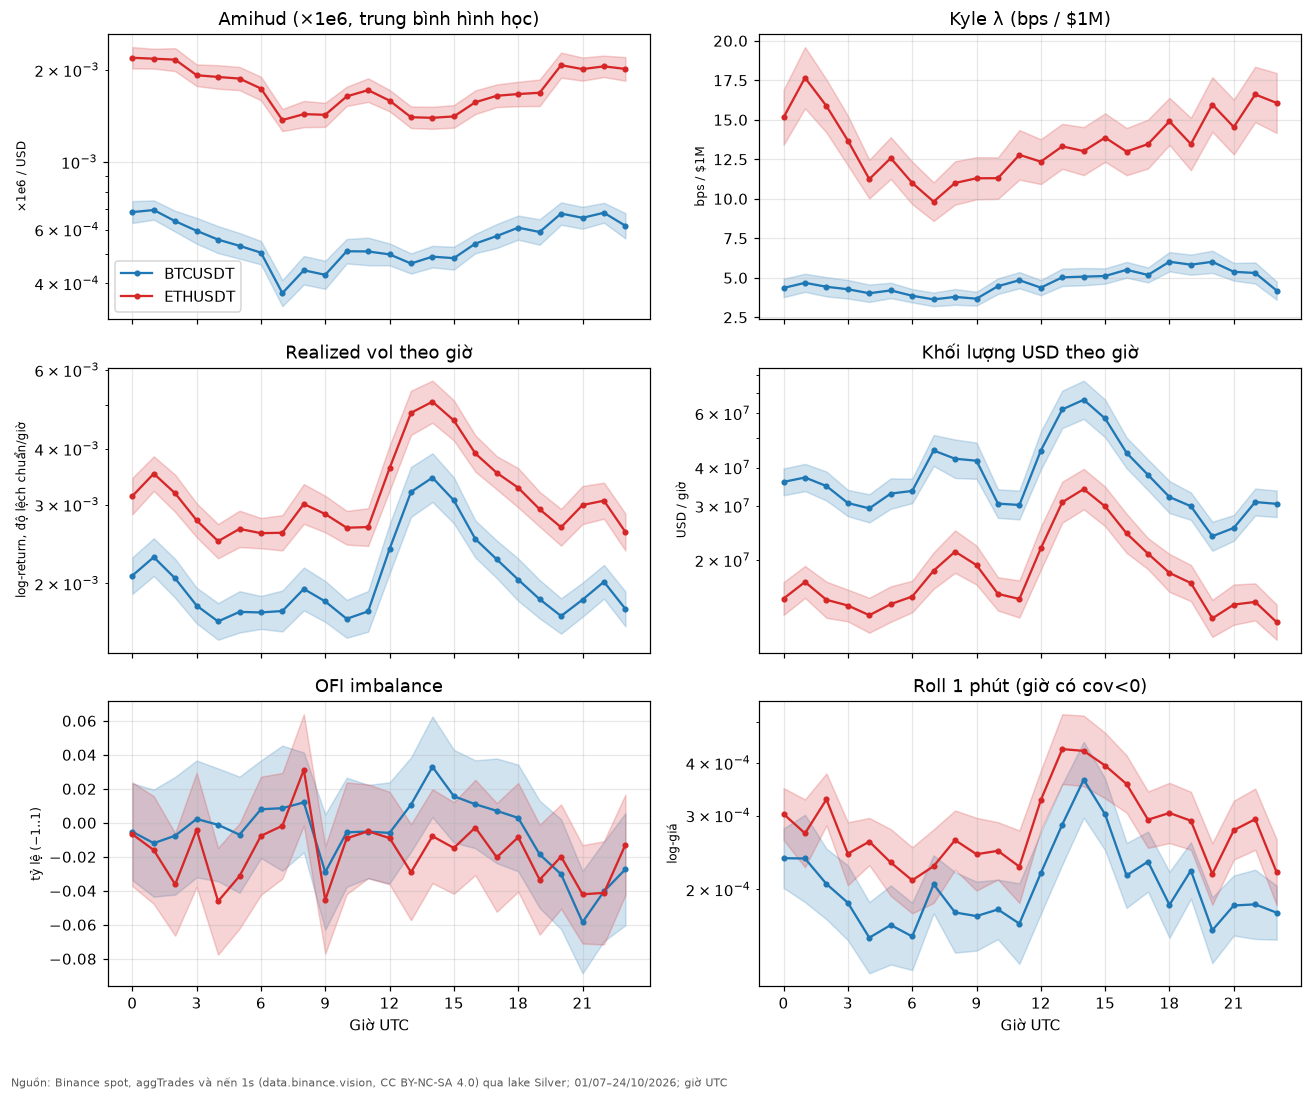

In [6]:
def hod_profile(col, log=True):
    d = H[["symbol", "hod", col]].dropna()
    v = np.log(d[col]) if log else d[col]
    d = d.assign(v=v)
    p = d.groupby(["symbol", "hod"])["v"].agg(["mean", "sem"])
    p["lo"], p["hi"] = p["mean"] - 1.96 * p["sem"], p["mean"] + 1.96 * p["sem"]
    if log: p[["mean", "lo", "hi"]] = np.exp(p[["mean", "lo", "hi"]])
    return p

panels = [("amihud", "Amihud (×1e6, trung bình hình học)", True), ("kyle", "Kyle λ (bps / $1M)", False),
          ("rv", "Realized vol theo giờ", True), ("usd_vol", "Khối lượng USD theo giờ", True),
          ("imb", "OFI imbalance", False), ("roll_1m", "Roll 1 phút (giờ có cov<0)", True)]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for ax, (col, title, lg) in zip(axes.flat, panels):
    p = hod_profile(col, lg)
    for s, q in p.groupby(level=0):
        q = q.droplevel(0)
        ax.plot(q.index, q["mean"], marker="o", ms=3, color=COL.get(s), label=s)
        ax.fill_between(q.index, q["lo"], q["hi"], color=COL.get(s), alpha=.2)
    ax.set_title(title); ax.set_yscale("log" if lg else "linear")
    ax.set_ylabel({"amihud": "×1e6 / USD", "kyle": "bps / $1M", "rv": "log-return, độ lệch chuẩn/giờ", "usd_vol": "USD / giờ",
                   "imb": "tỷ lệ (−1..1)", "roll_1m": "log-giá"}[col], fontsize=8)
for ax in axes[-1]: ax.set_xlabel("Giờ UTC"); ax.set_xticks(range(0, 24, 3))
axes[0, 0].legend(); finish(fig); fig.savefig(FIG_DIR / "model_hod_profiles.png", bbox_inches="tight")

In [7]:
# Kiểm định hiệu ứng giờ: hồi quy log(Amihud) theo dummy giờ, sai số HAC theo ngày
for s, d in H.dropna(subset=["amihud"]).groupby("symbol"):
    X = pd.get_dummies(d["hod"], prefix="h", drop_first=True, dtype=float)
    fit = sm.OLS(np.log(d["amihud"]), sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
    f = fit.wald_test(np.eye(len(fit.params))[1:], scalar=True)   # H0: không có hiệu ứng giờ
    hod = d.groupby("hod")["amihud"].median()
    print(f"{s}: Wald p = {float(f.pvalue):.2e}; Amihud thấp nhất lúc {hod.idxmin()}h, cao nhất lúc {hod.idxmax()}h UTC; max/min = {hod.max()/hod.min():.2f}")

BTCUSDT: Wald p = 5.78e-62; Amihud thấp nhất lúc 7h, cao nhất lúc 1h UTC; max/min = 1.88
ETHUSDT: Wald p = 1.78e-47; Amihud thấp nhất lúc 7h, cao nhất lúc 0h UTC; max/min = 1.65


### 3b. Proxy spread từ high/low (Corwin–Schultz 2012, Abdi–Ranaldo 2017) và hồ sơ giờ chung

Brauneis et al. (2021, *JBF*) cho thấy với crypto, Corwin–Schultz (CS) và Abdi–Ranaldo (AR) bám theo biến thiên thanh khoản theo thời gian tốt nhất, còn Amihud phù hợp để so **mức**. Ở đây CS và AR tính trên các cặp phút liên tiếp, với high/low/close dựng từ nến 1s, rồi lấy trung bình theo giờ. CS âm được đặt bằng 0, AR lấy $\sqrt{\max(\cdot,0)}$.

Lưu ý cách đọc: **Amihud theo giờ đo biến động giá trên mỗi USD giao dịch** (price impact), không phải spread. Giờ ít volume có mẫu số nhỏ nên Amihud tự nhiên cao.

In [8]:
k = 3 - 2 * np.sqrt(2)
m = m.sort_values(["symbol", "ts"])
nxt = m.groupby("symbol")[["high_1s", "low_1s", "close_1s", "ts"]].shift(-1)
consec = (nxt["ts"] - m["ts"]) == pd.Timedelta("1min")
lh, ll = np.log(m["high_1s"]), np.log(m["low_1s"])
beta = (lh - ll) ** 2 + (np.log(nxt["high_1s"]) - np.log(nxt["low_1s"])) ** 2
gamma = (np.log(np.maximum(m["high_1s"], nxt["high_1s"])) - np.log(np.minimum(m["low_1s"], nxt["low_1s"]))) ** 2
alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
m["cs"] = np.where(consec, (2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))).clip(lower=0), np.nan)
eta, eta1 = (lh + ll) / 2, (np.log(nxt["high_1s"]) + np.log(nxt["low_1s"])) / 2
c_ = np.log(m["close_1s"])
m["ar_term"] = np.where(consec, (c_ - eta) * (c_ - eta1), np.nan)

g2 = m.groupby(["symbol", "hour"])
spr = pd.DataFrame({"cs": g2["cs"].mean(), "ar": np.sqrt((4 * g2["ar_term"].mean()).clip(lower=0))}).reset_index()
spr["ar"] = spr["ar"].replace(0, np.nan)
H = H.drop(columns=[c for c in ["cs", "ar"] if c in H]).merge(spr, on=["symbol", "hour"], how="left")
H["amihud_per_vol"] = H["amihud"] / H["rv"]         # Amihud chuẩn hoá theo biến động của giờ
H.groupby("symbol")[["cs", "ar"]].agg(["median", lambda s: s.isna().mean()]).rename(columns={"<lambda_0>": "NaN rate"})

cs                  ar         
           median  NaN rate    median NaN rate
symbol                                        
BTCUSDT 6.338e-05 0.0003608 0.0001043   0.6201
ETHUSDT 0.0001115 0.0003608  0.000144   0.5523

Tương quan hồ sơ 24 giờ giữa các thước đo:
BTCUSDT


,usd_vol,rv,amihud,cs,ar,kyle
usd_vol,1,0.89,-0.58,0.88,0.86,0.03
rv,0.89,1,-0.2,0.99,0.95,0.36
amihud,-0.58,-0.2,1,-0.18,-0.23,0.32
cs,0.88,0.99,-0.18,1,0.93,0.38
ar,0.86,0.95,-0.23,0.93,1,0.3
kyle,0.03,0.36,0.32,0.38,0.3,1


ETHUSDT


,usd_vol,rv,amihud,cs,ar,kyle
usd_vol,1,0.93,-0.73,0.92,0.85,-0.19
rv,0.93,1,-0.44,0.98,0.91,0.15
amihud,-0.73,-0.44,1,-0.43,-0.43,0.69
cs,0.92,0.98,-0.43,1,0.91,0.15
ar,0.85,0.91,-0.43,0.91,1,0.08
kyle,-0.19,0.15,0.69,0.15,0.08,1


Giờ đỉnh / đáy theo từng thước đo:


idxmax          idxmin        
        BTCUSDT ETHUSDT BTCUSDT ETHUSDT
usd_vol      14      14      20      23
rv           14      14       4       4
amihud        1       0       7       7
cs           14      14       4       4
ar           14      14       6      23
kyle         18       1       7       7

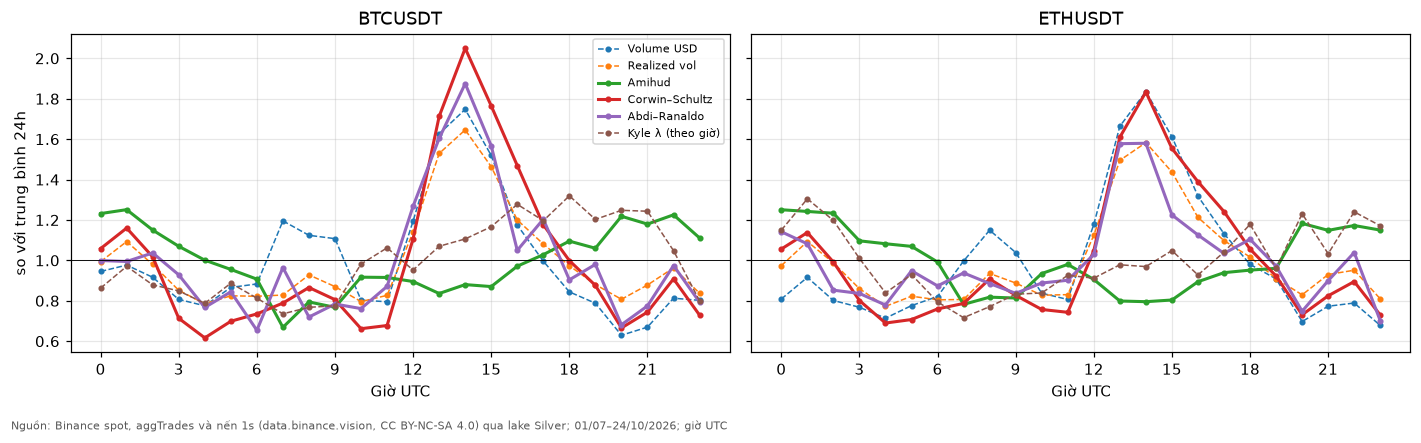

In [9]:
# Hồ sơ giờ chung: mỗi đường là trung bình hình học theo giờ chia cho trung bình 24 giờ (=1)
cols = {"usd_vol": "Volume USD", "rv": "Realized vol", "amihud": "Amihud", "cs": "Corwin–Schultz", "ar": "Abdi–Ranaldo",
        "kyle": "Kyle λ (theo giờ)"}
fig, axes = plt.subplots(1, H.symbol.nunique(), figsize=(13, 4), sharey=True, squeeze=False)
shape_tab = {}
for ax, (s, d) in zip(axes[0], H.groupby("symbol")):
    for c, lab in cols.items():
        x = d[d[c] > 0].groupby("hod")[c].apply(lambda v: np.exp(np.log(v).mean()))
        x = x / x.mean(); shape_tab[(s, c)] = x
        ax.plot(x.index, x.values, marker="o", ms=3, label=lab, lw=2 if c in ("amihud", "cs", "ar") else 1,
                ls="-" if c in ("amihud", "cs", "ar") else "--")
    ax.axhline(1, color="k", lw=.6); ax.set_title(s); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Giờ UTC")
axes[0, 0].set_ylabel("so với trung bình 24h"); axes[0, 0].legend(fontsize=7)
finish(fig); fig.savefig(FIG_DIR / "model_joint_hod_profile.png", bbox_inches="tight")
shape = pd.DataFrame(shape_tab)
print("Tương quan hồ sơ 24 giờ giữa các thước đo:")
for s in H.symbol.unique():
    print(s); display(shape[s].corr().round(2))
print("Giờ đỉnh / đáy theo từng thước đo:")
display(pd.DataFrame({c: shape.xs(c, axis=1, level=1).agg(["idxmax", "idxmin"]).stack() for c in cols}).T)

**Đọc kết quả (a).** So sánh hình dạng của Amihud với CS/AR và volume trong bảng tương quan phía trên. Nếu CS/AR đạt đỉnh ở giờ khác Amihud (ví dụ cùng chiều với realized vol vào phiên Mỹ), thì hai họ thước đo đang đo hai thứ khác nhau: CS/AR là spread hiệu dụng, gắn với biến động; Amihud là tác động giá trên mỗi USD, gắn nghịch với volume. Đây là một kết quả cần trình bày, không phải mâu thuẫn cần che đi. Brauneis et al. (2024) thấy illiquidity cùng đỉnh với volume và biến động lúc 16–17h UTC trên 1.940 cặp và 38 sàn; mẫu đó chủ yếu là cặp nhỏ, khác với BTC/ETH trên Binance.

## 4. Variance ratio (Lo–MacKinlay)

$VR(q) = \mathrm{Var}(r_t^{(q)}) / (q\,\mathrm{Var}(r_t))$ trên return 1 phút, với return q-phút chồng lấn. $z^*$ là thống kê bền với phương sai thay đổi (Lo & MacKinlay 1988). VR < 1 cho thấy mean reversion (nhiễu vi cấu trúc), VR > 1 cho thấy momentum.

In [10]:
def vr_test(r, q):
    r = np.asarray(r, float); r = r[~np.isnan(r)]
    T = len(r); mu = r.mean(); e = r - mu
    s1 = (e ** 2).sum() / (T - 1)
    rq = np.convolve(r, np.ones(q), "valid") - q * mu
    m_ = q * (T - q + 1) * (1 - q / T)
    sq = (rq ** 2).sum() / m_
    vr = sq / s1
    e2 = e ** 2
    delta = [((e2[j:] * e2[:-j]).sum()) / (e2.sum() ** 2) * T for j in range(1, q)]
    theta = sum((2 * (q - j) / q) ** 2 * delta[j - 1] for j in range(1, q))
    z = (vr - 1) / np.sqrt(theta / T) if theta > 0 else np.nan
    return vr, z, 2 * (1 - stats.norm.cdf(abs(z)))

QS = [5, 15, 60]
rows = []
for s, d in m.groupby("symbol"):
    for q in QS:
        vr, z, p = vr_test(d["r"].fillna(0).values, q)
        rows.append(dict(symbol=s, q=q, VR=vr, z_robust=z, p=p))
pd.DataFrame(rows).pivot(index="q", columns="symbol")

VR         z_robust               p        
symbol BTCUSDT ETHUSDT  BTCUSDT ETHUSDT BTCUSDT ETHUSDT
q                                                      
5       0.9973  0.9905  -0.1793 -0.4142  0.8577  0.6787
15      0.9668  0.9679   -1.323 -0.9301  0.1858  0.3523
60      0.9647  0.9887  -0.8407 -0.2107  0.4005  0.8331

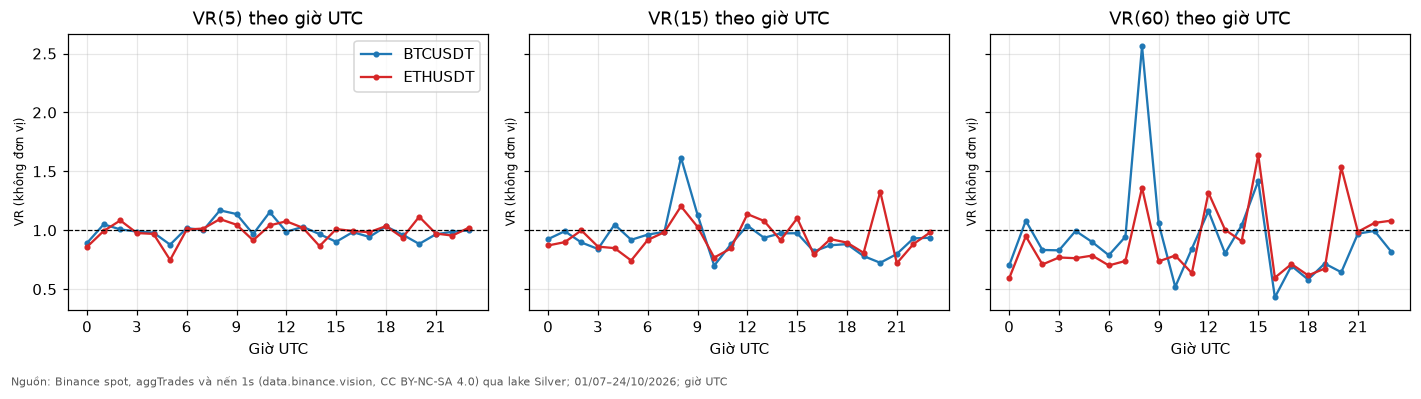

In [11]:
# VR theo giờ trong ngày: return q-phút nằm trọn trong giờ h, gộp qua các ngày
def vr_by_hod(d, q):
    out = {}
    for h, x in d.groupby(d["ts"].dt.hour):
        x = x.dropna(subset=["r"])
        blk = x.groupby([x["ts"].dt.floor("h"), x["ts"].dt.minute // q])["r"].agg(["sum", "size"])
        blk = blk[blk["size"] == q]["sum"]
        out[h] = blk.var() / (q * x["r"].var()) if len(blk) > 30 else np.nan
    return pd.Series(out)

fig, axes = plt.subplots(1, len(QS), figsize=(13, 3.6), sharey=True)
VRH = {}
for ax, q in zip(axes, QS):
    for s, d in m.groupby("symbol"):
        v = vr_by_hod(d, q); VRH[(s, q)] = v
        ax.plot(v.index, v.values, marker="o", ms=3, color=COL.get(s), label=s)
    ax.axhline(1, color="k", lw=.8, ls="--"); ax.set_title(f"VR({q}) theo giờ UTC"); ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Giờ UTC"); ax.set_ylabel("VR (không đơn vị)", fontsize=8)
axes[0].legend(); finish(fig); fig.savefig(FIG_DIR / "model_vr_by_hour.png", bbox_inches="tight")

### 4b. Kyle λ gộp theo giờ trong ngày (bin 10 giây)

Hồi quy $r_{	au} = a + \lambda\, 	ext{flow}_{	au} + \lambda_1\, 	ext{flow}_{	au-1} + e$ trên các bin 10 giây, gộp mọi ngày cho cùng một giờ UTC (khoảng 360 × 115 ≈ 41.000 quan sát mỗi giờ). Sai số chuẩn được cụm theo ngày. Có hai đơn vị:
- **λ (bps / $1M):** tác động giá của 1 triệu USD dòng lệnh ròng, dùng để so mức chi phí tuyệt đối.
- **λ chuẩn hoá** $=\lambda\cdot\sigma_{flow}/\sigma_r$: phần độ lệch chuẩn của return do một độ lệch chuẩn dòng lệnh gây ra, không phụ thuộc thang volume. Dùng để so BTC và ETH công bằng.

,lambda_bps_per_M,lo,hi,lambda_std,lambda_std_lo,lambda_std_hi,R2,n
symbol,,,,,,,,
BTCUSDT,2.758,2.459,3.057,0.425,0.3789,0.4712,0.1782,9.979e+05
ETHUSDT,7.785,6.623,8.948,0.4119,0.3504,0.4734,0.1661,9.961e+05


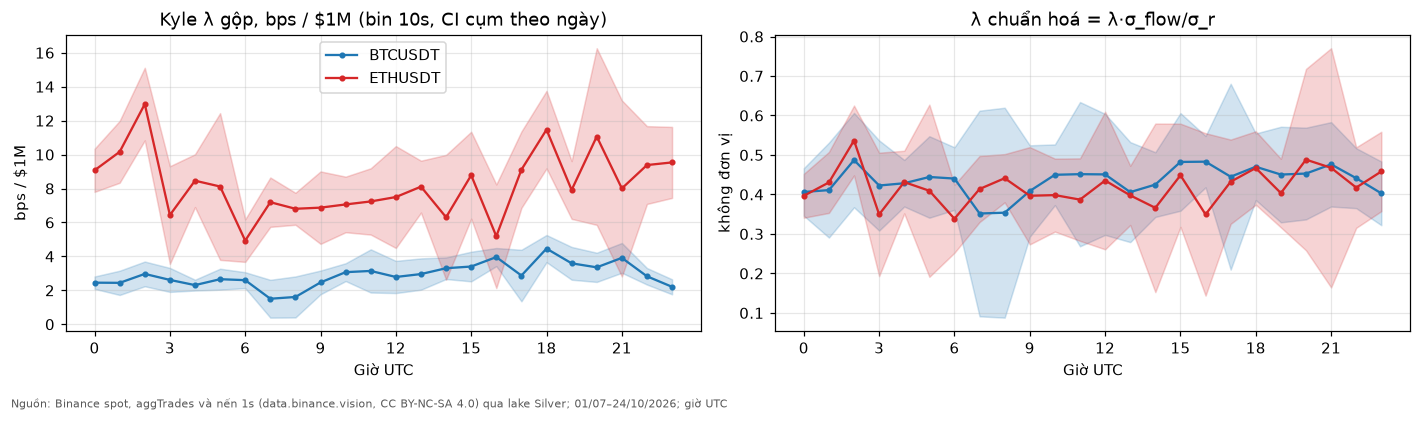

In [12]:
fl = pd.read_parquet(DATA_DIR / "flow_10s.parquet")
fl["ts"] = pd.to_datetime(fl["ts"], utc=True)
fl = in_period(fl, "ts")
fl = fl.sort_values(["symbol", "ts"])
prev = fl.groupby("symbol")["ts"].shift()
fl["r_bps"] = np.where(fl["ts"] - prev == pd.Timedelta("10s"), fl.groupby("symbol")["close"].transform(lambda p: np.log(p).diff()) * 1e4, np.nan)
fl["flow_M"] = fl["signed_usd"] / 1e6
fl["flow_M_l1"] = np.where(fl["ts"] - prev == pd.Timedelta("10s"), fl.groupby("symbol")["flow_M"].shift(), np.nan)
fl["day"] = fl["ts"].dt.floor("D"); fl["hod"] = fl["ts"].dt.hour; fl["month"] = fl["ts"].dt.strftime("%Y-%m")

def pooled_lambda(d):
    d = d.dropna(subset=["r_bps", "flow_M", "flow_M_l1"])
    fit = sm.OLS(d["r_bps"], sm.add_constant(d[["flow_M", "flow_M_l1"]])).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["day"])[0]})
    lam, se = fit.params["flow_M"], fit.bse["flow_M"]
    k_ = d["flow_M"].std() / d["r_bps"].std()
    return pd.Series({"lambda_bps_per_M": lam, "lo": lam - 1.96 * se, "hi": lam + 1.96 * se,
                      "lambda_std": lam * k_, "lambda_std_lo": (lam - 1.96 * se) * k_, "lambda_std_hi": (lam + 1.96 * se) * k_,
                      "R2": fit.rsquared, "n": len(d)})

LAM_ALL = fl.groupby("symbol").apply(pooled_lambda)
display(LAM_ALL)
LAM_HOD = fl.groupby(["symbol", "hod"]).apply(pooled_lambda)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for s, q in LAM_HOD.groupby(level=0):
    q = q.droplevel(0)
    axes[0].plot(q.index, q["lambda_bps_per_M"], marker="o", ms=3, color=COL.get(s), label=s)
    axes[0].fill_between(q.index, q["lo"], q["hi"], color=COL.get(s), alpha=.2)
    axes[1].plot(q.index, q["lambda_std"], marker="o", ms=3, color=COL.get(s), label=s)
    axes[1].fill_between(q.index, q["lambda_std_lo"], q["lambda_std_hi"], color=COL.get(s), alpha=.2)
axes[0].set_title("Kyle λ gộp, bps / $1M (bin 10s, CI cụm theo ngày)"); axes[1].set_title("λ chuẩn hoá = λ·σ_flow/σ_r")
for ax in axes: ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Giờ UTC")
axes[0].set_ylabel("bps / $1M"); axes[1].set_ylabel("không đơn vị")
axes[0].legend(); finish(fig); fig.savefig(FIG_DIR / "model_kyle_pooled_hod.png", bbox_inches="tight")

### 4c. Variance ratio theo phiên: Á (00–08), Âu (08–14), Mỹ (14–22 UTC)

Trong mỗi ngày, return q-phút được lấy theo các khối không chồng lấn nằm trọn trong phiên; VR là tỷ số $\mathrm{Var}(r^{(q)})/(q\,\mathrm{Var}(r))$, gộp qua các ngày. CI 95% có được bằng bootstrap lấy lại *theo ngày* (1.000 lần), nên vẫn giữ cấu trúc nội ngày. Giờ 22–24 không thuộc phiên nào nên bị bỏ. **Sức mạnh kiểm định thấp:** CI chứa 1 chỉ có nghĩa là *không bác bỏ* bước ngẫu nhiên, không chứng minh thị trường hiệu quả.

,symbol,session,q,VR,ci_lo,ci_hi,n_days,reject_RW
0,BTCUSDT,Á 00–08,5,0.977,0.923,1.028,116,False
1,BTCUSDT,Á 00–08,15,0.943,0.88,1.023,116,False
2,BTCUSDT,Á 00–08,60,0.887,0.788,0.983,116,True
3,BTCUSDT,Âu 08–14,5,1.061,0.998,1.132,116,False
4,BTCUSDT,Âu 08–14,15,1.055,0.957,1.158,116,False
5,BTCUSDT,Âu 08–14,60,1.146,0.901,1.373,116,False
6,BTCUSDT,Mỹ 14–22,5,0.953,0.888,1.012,115,False
7,BTCUSDT,Mỹ 14–22,15,0.895,0.837,0.954,115,True
8,BTCUSDT,Mỹ 14–22,60,0.92,0.761,1.079,115,False
9,ETHUSDT,Á 00–08,5,0.947,0.843,1.031,116,False


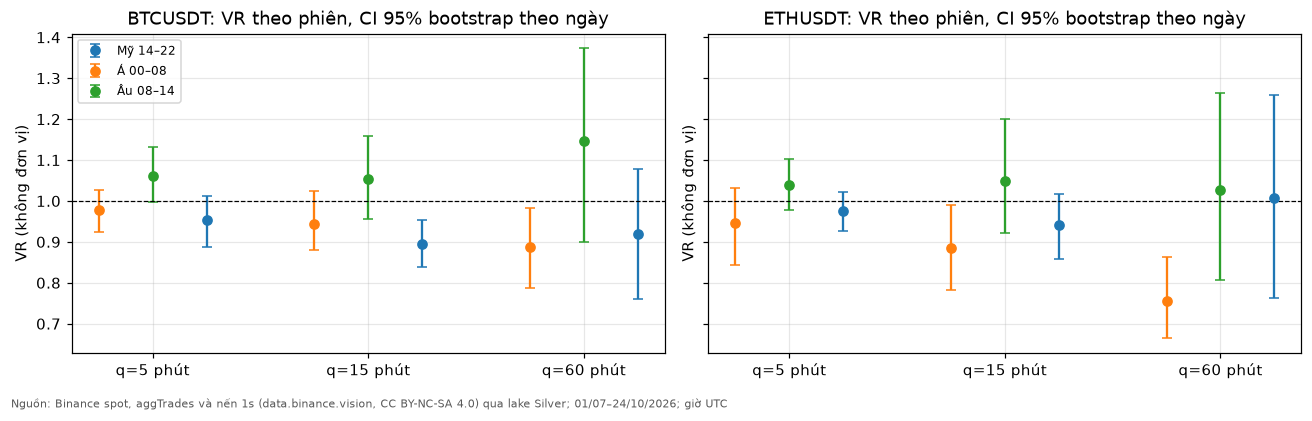

In [13]:
SESS = {"Á 00–08": (0, 8), "Âu 08–14": (8, 14), "Mỹ 14–22": (14, 22)}

def vr_session_stats(x, q):
    # x: minutes of one session (all days); returns per-day (sum r_q^2 over blocks, n_blocks, sum r^2, n) for bootstrap
    x = x.dropna(subset=["r"])
    day = x["ts"].dt.floor("D")
    blk_id = (x["ts"] - day) // pd.Timedelta(f"{q}min")
    b = x.groupby([day, blk_id])["r"].agg(["sum", "size"])
    b = b[b["size"] == q]
    per_q = b.groupby(level=0)["sum"].agg(s2=lambda v: (v ** 2).sum(), nb="size", s1="sum")
    per_1 = x.groupby(day)["r"].agg(r2=lambda v: (v ** 2).sum(), n="size", r1="sum")
    return per_q.join(per_1, how="inner")

def vr_from(t, q):
    mq = t["s1"].sum() / t["nb"].sum(); m1 = t["r1"].sum() / t["n"].sum()
    vq = t["s2"].sum() / t["nb"].sum() - mq ** 2; v1 = t["r2"].sum() / t["n"].sum() - m1 ** 2
    return vq / (q * v1)

rng_vr = np.random.default_rng(SEED)
rows = []
for s, d in m.groupby("symbol"):
    for name, (h0, h1) in SESS.items():
        x = d[(d["ts"].dt.hour >= h0) & (d["ts"].dt.hour < h1)]
        for q in QS:
            t = vr_session_stats(x, q)
            boot = [vr_from(t.iloc[rng_vr.integers(0, len(t), len(t))], q) for _ in range(1000)]
            lo, hi = np.percentile(boot, [2.5, 97.5])
            rows.append(dict(symbol=s, session=name, q=q, VR=vr_from(t, q), ci_lo=lo, ci_hi=hi, n_days=len(t),
                             reject_RW=not (lo <= 1 <= hi)))
VRS = pd.DataFrame(rows)
display(VRS.round(3))

fig, axes = plt.subplots(1, VRS.symbol.nunique(), figsize=(12, 3.8), sharey=True, squeeze=False)
off = {"Á 00–08": -0.25, "Âu 08–14": 0, "Mỹ 14–22": 0.25}
for ax, (s, d) in zip(axes[0], VRS.groupby("symbol")):
    for name, g_ in d.groupby("session"):
        xs = np.arange(len(QS)) + off[name]
        ax.errorbar(xs, g_["VR"], yerr=[g_["VR"] - g_["ci_lo"], g_["ci_hi"] - g_["VR"]], fmt="o", capsize=3, label=name)
    ax.axhline(1, color="k", lw=.8, ls="--"); ax.set_xticks(range(len(QS))); ax.set_xticklabels([f"q={q} phút" for q in QS])
    ax.set_title(f"{s}: VR theo phiên, CI 95% bootstrap theo ngày"); ax.set_ylabel("VR (không đơn vị)")
axes[0, 0].legend(fontsize=8); finish(fig); fig.savefig(FIG_DIR / "model_vr_by_session.png", bbox_inches="tight")

## 5. So sánh giai đoạn và tài sản

Giai đoạn yên tĩnh là tháng trọn vẹn có realized vol trung vị thấp nhất, giai đoạn biến động là tháng có realized vol trung vị cao nhất, xếp hạng theo BTC. Tháng 10 chưa trọn (đến 24/10) nên chỉ được chọn khi có ít nhất 20 ngày dữ liệu. Kiểm định Mann–Whitney trên giá trị theo ngày (trung bình các giờ trong ngày) để giảm tự tương quan giữa các giờ.

In [14]:
H["day"] = H["hour"].dt.floor("D")
D = H.groupby(["symbol", "day"]).agg(amihud=("amihud", "median"), kyle=("kyle", "median"),
                                     rv=("rv", "median"), roll_1m=("roll_1m", "median"),
                                     usd_vol=("usd_vol", "sum")).reset_index()
D["month"] = D["day"].dt.strftime("%Y-%m")
ndays = D[D.symbol == "BTCUSDT"].groupby("month").size()
vol_m = D[D.symbol == "BTCUSDT"].groupby("month")["rv"].median()[ndays >= 20]
CALM, VOLATILE = vol_m.idxmin(), vol_m.idxmax()
print("RV trung vị theo tháng (BTC):", vol_m.round(5).to_dict()); print("Yên tĩnh:", CALM, "| Biến động:", VOLATILE)

def compare(a, b, cols=("amihud", "kyle", "rv", "roll_1m", "usd_vol")):
    out = []
    for c in cols:
        x, y = a[c].dropna(), b[c].dropna()
        out.append(dict(metric=c, A_median=x.median(), B_median=y.median(), ratio_B_over_A=y.median() / x.median(),
                        p_mannwhitney=stats.mannwhitneyu(x, y).pvalue))
    return pd.DataFrame(out).set_index("metric")

print("\n== Giai đoạn: A = yên tĩnh, B = biến động ==")
period_tab = {s: compare(d[d.month == CALM], d[d.month == VOLATILE]) for s, d in D.groupby("symbol")}
display(pd.concat(period_tab, names=["symbol"]))
print("\n== Tài sản: A = BTCUSDT, B = asset còn lại (cùng ngày) ==")
for s in [x for x in D.symbol.unique() if x != "BTCUSDT"]:
    display(compare(D[D.symbol == "BTCUSDT"], D[D.symbol == s]).rename(columns={"B_median": f"{s}_median"}))

RV trung vị theo tháng (BTC): {'2026-07': 0.00216, '2026-08': 0.00176, '2026-09': 0.00241, '2026-10': 0.002}
Yên tĩnh: 2026-08 | Biến động: 2026-09

== Giai đoạn: A = yên tĩnh, B = biến động ==


A_median  B_median  ratio_B_over_A  p_mannwhitney
symbol  metric                                                    
BTCUSDT amihud  0.0005816  0.000519          0.8924         0.8682
        kyle        4.937     4.153          0.8412         0.2017
        rv       0.001756  0.002414           1.374         0.1077
        roll_1m 0.0001708 0.0002158           1.264         0.1821
        usd_vol  8.69e+08 1.159e+09           1.333        0.05594
ETHUSDT amihud   0.001643  0.001407          0.8562       0.003486
        kyle        13.27     9.894          0.7454      2.152e-05
        rv       0.002548   0.00337           1.323        0.05412
        roll_1m 0.0002884 0.0003093           1.072         0.1354
        usd_vol 3.628e+08 7.228e+08           1.992        0.01045


== Tài sản: A = BTCUSDT, B = asset còn lại (cùng ngày) ==


,A_median,ETHUSDT_median,ratio_B_over_A,p_mannwhitney
metric,,,,
amihud,0.0005811,0.001757,3.024,3.259e-38
kyle,4.126,11.81,2.863,5.441e-39
rv,0.002061,0.003228,1.566,8.234e-15
roll_1m,0.0002167,0.0003037,1.401,1.755e-11
usd_vol,1.094e+09,5.438e+08,0.497,2.142e-17


### 5b. Độ bền của so sánh hai giai đoạn

Tỷ lệ Amihud giữa hai tháng phần nào là kết quả cơ học: Amihud là |r| chia volume, nên khi volume tăng nhanh hơn biến động thì Amihud giảm. Mỗi giai đoạn cũng chỉ là một tháng. Vì vậy phần này bổ sung:
- **Effect size** là log của tỷ lệ trung vị, với **CI 95% từ block bootstrap** (khối 3 ngày, lấy mẫu lại trong từng tháng, 2.000 lần), và Cliff's δ.
- Các thước đo **không thuần là tỷ lệ với volume**: Amihud/σ, CS, AR, và λ chuẩn hoá theo ngày.
- **Placebo:** so nửa đầu với nửa sau của *cùng* một tháng. Nếu placebo cho hiệu lớn cỡ hiệu giữa hai tháng, thì hiệu giữa hai tháng chỉ là nhiễu lịch.

Notebook không gắn hiệu này với sự kiện cụ thể (tin vĩ mô, thanh lý) vì dữ liệu không có trường sự kiện. Đây là mô tả, không phải quan hệ nhân quả.

In [15]:
rng_ = np.random.default_rng(SEED)
lam_day = fl.dropna(subset=["r_bps", "flow_M"]).groupby(["symbol", "day"]).apply(
    lambda d: np.cov(d["flow_M"], d["r_bps"])[0, 1] / d["flow_M"].var() * d["flow_M"].std() / d["r_bps"].std()).rename("lambda_std")
D2 = H.groupby(["symbol", "day"]).agg(amihud=("amihud", "median"), amihud_per_vol=("amihud_per_vol", "median"),
                                      cs=("cs", "median"), ar=("ar", "median"), rv=("rv", "median"),
                                      usd_vol=("usd_vol", "sum")).join(lam_day).reset_index()
D2["month"] = D2["day"].dt.strftime("%Y-%m")
METRICS = ["usd_vol", "rv", "amihud", "amihud_per_vol", "cs", "ar", "lambda_std"]

def block_boot_logratio(a, b, block=3, B=2000):
    a, b = np.asarray(a), np.asarray(b)
    def draw(x):
        nb = int(np.ceil(len(x) / block)); st = rng_.integers(0, len(x) - block + 1, nb)
        return np.concatenate([x[i:i + block] for i in st])[:len(x)]
    bs = [np.log(np.nanmedian(draw(b)) / np.nanmedian(draw(a))) for _ in range(B)]
    return np.percentile(bs, [2.5, 97.5])

def cliffs_delta(a, b):
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return ((b > a).mean() - (b < a).mean())

def robust_compare(a, b):
    rows = []
    for c in METRICS:
        x, y = a[c].dropna().values, b[c].dropna().values
        lo, hi = block_boot_logratio(x, y)
        rows.append(dict(metric=c, pct_change=np.exp(np.log(np.median(y) / np.median(x))) - 1,
                         log_ratio=np.log(np.median(y) / np.median(x)), ci_lo=lo, ci_hi=hi, cliffs_delta=cliffs_delta(x, y)))
    return pd.DataFrame(rows).set_index("metric")

ROB = {}
for s, d in D2.groupby("symbol"):
    ROB[(s, f"{CALM} -> {VOLATILE}")] = robust_compare(d[d.month == CALM], d[d.month == VOLATILE])
    for mon in (CALM, VOLATILE):                     # placebo: nửa đầu vs nửa sau cùng tháng
        dm = d[d.month == mon].sort_values("day"); h = len(dm) // 2
        ROB[(s, f"placebo {mon}: nửa đầu -> nửa sau")] = robust_compare(dm.iloc[:h], dm.iloc[h:])
ROBT = pd.concat(ROB, names=["symbol", "so sánh"])
ROBT["CI không chứa 0"] = (ROBT["ci_lo"] > 0) | (ROBT["ci_hi"] < 0)
display(ROBT.round(3))

pct_change  \
symbol  so sánh                             metric                       
BTCUSDT 2026-08 -> 2026-09                  usd_vol              0.333   
                                            rv                   0.374   
                                            amihud              -0.108   
                                            amihud_per_vol      -0.214   
                                            cs                   0.654   
                                            ar                     0.3   
                                            lambda_std          -0.052   
        placebo 2026-08: nửa đầu -> nửa sau usd_vol               0.63   
                                            rv                   0.837   
                                            amihud              -0.055   
                                            amihud_per_vol      -0.346   
                                            cs                   1.198   
                                            ar                   0.558   
                                            lambda_std           0.006   
        placebo 2026-09: nửa đầu -> nửa sau usd_vol              0.364   
                                            rv                   -0.09   
                                            amihud              -0.137   
                                            amihud_per_vol      -0.117   
                                            cs                   -0.06   
                                            ar                   0.281   
                                            lambda_std           0.008   
ETHUSDT 2026-08 -> 2026-09                  usd_vol              0.992   
                                            rv                   0.323   
                                            amihud              -0.144   
                                            amihud_per_vol      -0.492   
                                            cs                    0.65   
                                            ar                   0.395   
                                            lambda_std          -0.004   
        placebo 2026-08: nửa đầu -> nửa sau usd_vol              1.606   
                                            rv                   0.658   
                                            amihud              -0.324   
                                            amihud_per_vol      -0.567   
                                            cs                   1.195   
                                            ar                    0.46   
                                            lambda_std           -0.02   
        placebo 2026-09: nửa đầu -> nửa sau usd_vol              0.071   
                                            rv                   0.091   
                                            amihud                0.15   
                                            amihud_per_vol       0.145   
                                            cs                   0.146   
                                            ar                   0.138   
                                            lambda_std          -0.157   

                                                            log_ratio  ci_lo  \
symbol  so sánh                             metric                             
BTCUSDT 2026-08 -> 2026-09                  usd_vol             0.288 -0.116   
                                            rv                  0.318 -0.112   
                                            amihud             -0.114 -0.278   
                                            amihud_per_vol      -0.24 -0.447   
                                            cs                  0.503 -0.191   
                                            ar                  0.262 -0.046   
                                            lambda_std         -0.053 -0.103   
        placebo 2026-08: nửa đầu -> nửa sau usd_vol             0.488  0.102   
   

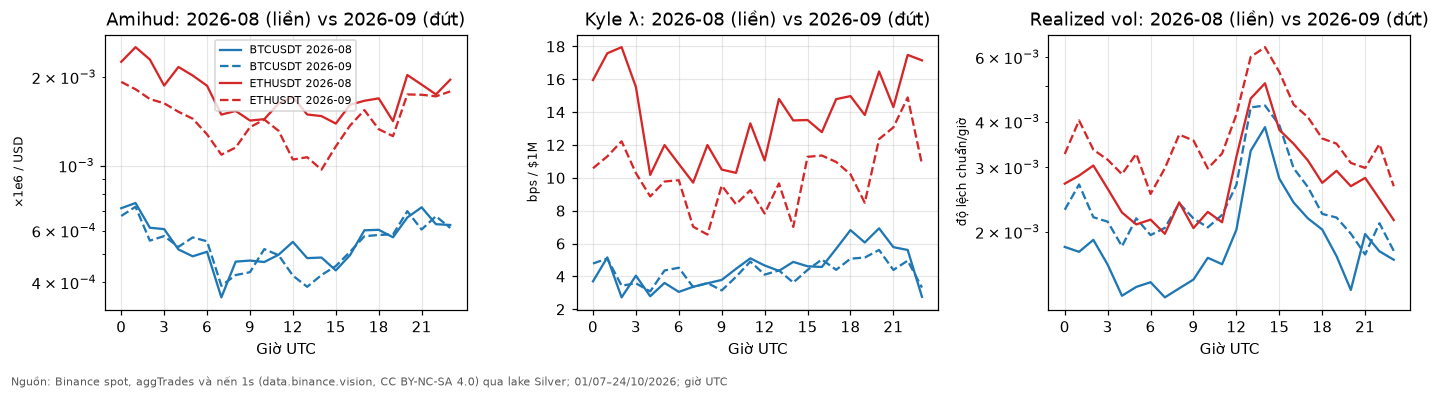

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, ttl in zip(axes, ["amihud", "kyle", "rv"], ["Amihud", "Kyle λ", "Realized vol"]):
    for s, d in H.groupby("symbol"):
        for mon, ls in [(CALM, "-"), (VOLATILE, "--")]:
            q = d[d.month == mon].groupby("hod")[col].median()
            ax.plot(q.index, q.values, ls=ls, color=COL.get(s), label=f"{s} {mon}")
    ax.set_title(f"{ttl}: {CALM} (liền) vs {VOLATILE} (đứt)"); ax.set_yscale("log" if col != "kyle" else "linear")
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Giờ UTC")
    ax.set_ylabel({"amihud": "×1e6 / USD", "kyle": "bps / $1M", "rv": "độ lệch chuẩn/giờ"}[col], fontsize=8)
axes[0].legend(fontsize=7); finish(fig); fig.savefig(FIG_DIR / "model_calm_vs_volatile.png", bbox_inches="tight")

## 6. Dự báo log(Amihud) giờ tới, có baseline và kiểm ngoài mẫu

- **Mục tiêu:** $y_{t+1} = \log \text{Amihud}_{t+1}$ của từng symbol.
- **Feature (chỉ dùng thông tin ≤ t):** HAR gồm trung bình log-Amihud của 1, 24, 168 giờ; giá trị cùng giờ hôm trước (lag 24 tính từ t+1, tức lag 23 tính từ t); log realized vol, log khối lượng USD, |OFI imbalance|, Kyle λ, return giờ, và sin/cos của giờ t+1.
- **Baseline chính là B0 (giờ liền trước).** Mùa vụ theo giờ rất mạnh, nên bảng còn có B2 (trung bình cùng giờ trên train) và mô hình HAR_hod (HAR + 23 dummy giờ). HAR gốc không có biến giờ.
- **Các baseline:** (B0) giờ liền trước $\hat y_{t+1}=y_t$; (B1) cùng giờ hôm trước $\hat y_{t+1}=y_{t-23}$; (B2) trung bình theo giờ trong ngày, tính trên tập train.
- **Model:** HAR-OLS (giải thích được) và LightGBM.
- **Chia mẫu:** theo thời gian, không xáo trộn. Train là tháng 7 đến 9, test là 1/10 đến 24/10. Kiểm tra thêm bằng walk-forward cửa sổ mở rộng, refit mỗi tuần.
- **Metric:** MAE và RMSE trên log; R²_OOS so với B1 và so với B0; kiểm định Diebold–Mariano so với B0 (baseline mạnh hơn), loss bình phương, sai số HAC.
- **Chống leakage:** Amihud mỗi giờ chỉ tính từ các phút trong giờ đó, không chuẩn hoá theo toàn mẫu. Rolling chỉ nhìn về quá khứ. OLS, LightGBM và trung bình theo giờ chỉ fit trên train. Cell kiểm tra ngay dưới đây assert các điều này.

In [17]:
def make_features(d, drop_target=True):
    d = d.sort_values("hour").set_index("hour").asfreq("h")     # lưới giờ đều; giờ thiếu = NaN
    y = np.log(d["amihud"])
    X = pd.DataFrame(index=d.index)
    X["la_1"] = y
    X["la_24"] = y.rolling(24, min_periods=18).mean()
    X["la_168"] = y.rolling(168, min_periods=120).mean()
    X["la_samehour"] = y.shift(23)                  # giá trị của giờ t+1-24
    X["lrv"] = np.log(d["rv"])
    X["lvol"] = np.log(d["usd_vol"])
    X["abs_imb"] = d["imb"].abs()
    X["kyle"] = d["kyle"]
    X["ret"] = d["ret"]
    hod1 = (d.index + pd.Timedelta("1h")).hour
    X["sin_h"], X["cos_h"] = np.sin(2 * np.pi * hod1 / 24), np.cos(2 * np.pi * hod1 / 24)
    X["hod_next"] = hod1
    X["y_next"] = y.shift(-1)
    X["symbol"] = d["symbol"].ffill().bfill()
    return X.dropna() if drop_target else X.dropna(subset=X.columns.drop("y_next"))

F = pd.concat([make_features(d) for _, d in H.groupby("symbol")]).reset_index()

FEATS_ALL = ["la_1", "la_24", "la_168", "la_samehour", "lrv", "lvol", "abs_imb", "kyle", "ret", "sin_h", "cos_h"]
# Kiểm tra leakage: mỗi feature ở dòng t chỉ dùng y của giờ <= t, còn mục tiêu là y của giờ t+1
_y = H.set_index(["symbol", "hour"])["amihud"].pipe(np.log)
_k = F.set_index(["symbol", "hour"])
assert np.allclose(_k["la_1"], _y.reindex(_k.index))
assert np.allclose(_k["y_next"], _y.reindex([(s, h + pd.Timedelta("1h")) for s, h in _k.index]))
assert np.allclose(_k["la_samehour"], _y.reindex([(s, h - pd.Timedelta("23h")) for s, h in _k.index]))
# Cắt bỏ toàn bộ dữ liệu sau giờ t rồi dựng lại feature: feature tại t phải không đổi
_b = H[H.symbol == "BTCUSDT"]
for _t in F[F.symbol == "BTCUSDT"]["hour"].iloc[[300, 1500, -50]]:
    _cut = make_features(_b[_b.hour <= _t], drop_target=False).loc[_t, FEATS_ALL]
    _full = F[(F.symbol == "BTCUSDT") & (F.hour == _t)].iloc[0][FEATS_ALL]
    assert np.allclose(_cut.astype(float), _full.astype(float)), _t
print("leakage checks OK")
TEST_START = pd.Timestamp("2026-10-01", tz="UTC")
HAR = ["la_1", "la_24", "la_168"]
FULL = HAR + ["la_samehour", "lrv", "lvol", "abs_imb", "kyle", "ret", "sin_h", "cos_h"]
F.groupby("symbol").size()

leakage checks OK


symbol
BTCUSDT    2652
ETHUSDT    2652
dtype: int64

In [18]:
import lightgbm as lgb

def fit_predict(tr, te):
    out = pd.DataFrame({"y": te["y_next"].values}, index=te.index)
    out["B0_prev_hour"] = te["la_1"].values          # giờ liền trước (t)
    out["B1_naive"] = te["la_samehour"].values       # cùng giờ hôm trước (t+1-24)
    hod_mean = tr.groupby("hod_next")["y_next"].mean()
    out["B2_hod_mean"] = te["hod_next"].map(hod_mean).values
    for name, cols in [("HAR", HAR), ("HAR_X", FULL)]:
        ols = sm.OLS(tr["y_next"], sm.add_constant(tr[cols])).fit()
        out[name] = ols.predict(sm.add_constant(te[cols], has_constant="add")).values
    # HAR + dummy giờ (mùa vụ theo giờ ước trên train)
    dtr = pd.get_dummies(tr["hod_next"], prefix="h", dtype=float).reindex(columns=[f"h_{i}" for i in range(1, 24)], fill_value=0)
    dte = pd.get_dummies(te["hod_next"], prefix="h", dtype=float).reindex(columns=dtr.columns, fill_value=0)
    ols_s = sm.OLS(tr["y_next"].values, sm.add_constant(np.column_stack([tr[HAR].values, dtr.values]))).fit()
    out["HAR_hod"] = ols_s.predict(sm.add_constant(np.column_stack([te[HAR].values, dte.values]), has_constant="add"))
    gbm = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    gbm.fit(tr[FULL], tr["y_next"])
    out["LightGBM"] = gbm.predict(te[FULL])
    return out, ols, gbm

def dm_test(e_model, e_base, h=1):
    # Diebold–Mariano, phương sai HAC (Newey–West, 24 lag), hiệu chỉnh mẫu nhỏ
    # Harvey–Leybourne–Newbold (1997), p-value từ t(n-1). > 0: model tốt hơn baseline
    d = e_base ** 2 - e_model ** 2
    n = len(d)
    fit = sm.OLS(d, np.ones(n)).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
    t = float(np.asarray(fit.tvalues)[0]) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return t, 2 * (1 - stats.t.cdf(abs(t), n - 1))

def score(out):
    rows = []
    e0 = out["y"] - out["B1_naive"]
    ep = out["y"] - out["B0_prev_hour"]
    es = out["y"] - out["B2_hod_mean"]
    for c in out.columns.drop("y"):
        e = out["y"] - out[c]
        t, p = dm_test(e.values, ep.values) if c != "B0_prev_hour" else (np.nan, np.nan)
        ts, ps = dm_test(e.values, es.values) if c != "B2_hod_mean" else (np.nan, np.nan)
        rows.append(dict(model=c, MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()),
                         R2_OOS_vs_naive=1 - (e ** 2).sum() / (e0 ** 2).sum(),
                         R2_OOS_vs_prev=1 - (e ** 2).sum() / (ep ** 2).sum(), DM_t_vs_prev=t, DM_p_vs_prev=p,
                         R2_OOS_vs_seasonal=1 - (e ** 2).sum() / (es ** 2).sum(), DM_t_vs_seasonal=ts, DM_p_vs_seasonal=ps))
    return pd.DataFrame(rows).set_index("model")

RES, MODELS, PRED = {}, {}, {}
for s, d in F.groupby("symbol"):
    tr, te = d[d.hour < TEST_START], d[d.hour >= TEST_START]
    out, ols, gbm = fit_predict(tr, te)
    out.index = te["hour"].values
    RES[s], MODELS[s], PRED[s] = score(out), (ols, gbm), out
    print(f"{s}: train {len(tr)} giờ, test {len(te)} giờ")
pd.concat(RES, names=["symbol"])

BTCUSDT: train 2089 giờ, test 563 giờ


ETHUSDT: train 2089 giờ, test 563 giờ


MAE   RMSE  R2_OOS_vs_naive  R2_OOS_vs_prev  \
symbol  model                                                         
BTCUSDT B0_prev_hour 0.2712 0.3591           0.5976               0   
        B1_naive     0.4273 0.5661                0          -1.485   
        B2_hod_mean  0.3417 0.4722           0.3041         -0.7293   
        HAR          0.2406 0.3214           0.6777          0.1989   
        HAR_X        0.2469 0.3227            0.675          0.1923   
        HAR_hod      0.2373 0.3157            0.689          0.2272   
        LightGBM     0.2536  0.334           0.6519          0.1349   
ETHUSDT B0_prev_hour   0.29 0.3772           0.6944               0   
        B1_naive     0.5331 0.6823                0          -2.273   
        B2_hod_mean  0.4102 0.5367           0.3813          -1.025   
        HAR           0.278 0.3508           0.7356          0.1349   
        HAR_X        0.2838 0.3573           0.7258          0.1026   
        HAR_hod      0.2757 0.3503           0.7364          0.1374   
        LightGBM     0.2862 0.3741           0.6994         0.01619   

                      DM_t_vs_prev  DM_p_vs_prev  R2_OOS_vs_seasonal  \
symbol  model                                                          
BTCUSDT B0_prev_hour           NaN           NaN              0.4217   
        B1_naive            -5.229     2.403e-07             -0.4371   
        B2_hod_mean         -2.407       0.01642                   0   
        HAR                  6.549      1.31e-10              0.5368   
        HAR_X                4.988     8.129e-07              0.5329   
        HAR_hod              7.611     1.152e-13              0.5531   
        LightGBM             2.573       0.01033              0.4997   
ETHUSDT B0_prev_hour           NaN           NaN              0.5061   
        B1_naive            -4.241     2.605e-05             -0.6162   
        B2_hod_mean         -2.758      0.005999                   0   
        HAR                  3.428     0.0006525              0.5727   
        HAR_X                1.651       0.09939              0.5568   
        HAR_hod              2.273       0.02338               0.574   
        LightGBM             0.156        0.8761              0.5141   

                      DM_t_vs_seasonal  DM_p_vs_seasonal  
symbol  model                                             
BTCUSDT B0_prev_hour             2.407           0.01642  
        B1_naive                -2.116           0.03479  
        B2_hod_mean                NaN               NaN  
        HAR                      2.965          0.003152  
        HAR_X                    2.929          0.003544  
        HAR_hod                  3.109          0.001971  
        LightGBM                 2.877          0.004163  
ETHUSDT B0_prev_hour             2.758          0.005999  
        B1_naive                -2.985          0.002956  
        B2_hod_mean                NaN               NaN  
        HAR                      3.288          0.001072  
        HAR_X                    3.388         0.0007545  
        HAR_hod                  3.513          0.000479  
        LightGBM                 3.642         0.0002957

In [19]:
# Walk-forward nhiều lần cắt: cửa sổ mở rộng, refit mỗi 7 ngày, từ 01/09 đến hết dữ liệu (~8 fold)
WF, FOLDS = {}, []
WF_START = pd.Timestamp("2026-09-01", tz="UTC")
for s, d in F.groupby("symbol"):
    outs = []
    for start in pd.date_range(WF_START, d.hour.max(), freq="7D"):
        tr = d[d.hour < start]; te = d[(d.hour >= start) & (d.hour < start + pd.Timedelta("7D"))]
        if len(te) < 48: continue
        o = fit_predict(tr, te)[0]; outs.append(o)
        sc = score(o)
        FOLDS.append(dict(symbol=s, fold_start=start.date(), n=len(te), **{f"R2_vs_prev_{c}": sc.loc[c, "R2_OOS_vs_prev"]
                                                                         for c in ["B2_hod_mean", "HAR", "HAR_hod", "HAR_X", "LightGBM"]},
                          R2_vs_seasonal_HAR_hod=sc.loc["HAR_hod", "R2_OOS_vs_seasonal"],
                          R2_vs_prev_HAR_hod_minus_HAR=sc.loc["HAR_hod", "R2_OOS_vs_prev"] - sc.loc["HAR", "R2_OOS_vs_prev"]))
    WF[s] = score(pd.concat(outs))
display(pd.concat(WF, names=["symbol"]))
FOLDS = pd.DataFrame(FOLDS)
display(FOLDS.round(3))
print("Theo fold: trung bình / min / tỷ lệ fold thắng B0")
display(FOLDS.groupby("symbol")[[c for c in FOLDS if c.startswith("R2_vs")]].agg(["mean", "min", lambda x: (x > 0).mean()]).round(3))

MAE   RMSE  R2_OOS_vs_naive  R2_OOS_vs_prev  \
symbol  model                                                         
BTCUSDT B0_prev_hour 0.2604 0.3432           0.5878               0   
        B1_naive     0.4054 0.5346                0          -1.426   
        B2_hod_mean  0.3256 0.4343           0.3401         -0.6009   
        HAR          0.2361 0.3102           0.6632           0.183   
        HAR_X        0.2357 0.3067            0.671          0.2017   
        HAR_hod      0.2271    0.3           0.6852          0.2362   
        LightGBM     0.2395 0.3157           0.6512          0.1538   
ETHUSDT B0_prev_hour 0.2751 0.3585           0.6357               0   
        B1_naive      0.465  0.594                0          -1.745   
        B2_hod_mean  0.3943 0.5082           0.2679           -1.01   
        HAR           0.258 0.3301           0.6911          0.1522   
        HAR_X        0.2578 0.3283           0.6944          0.1612   
        HAR_hod      0.2523 0.3236           0.7033          0.1855   
        LightGBM     0.2654 0.3414           0.6696          0.0931   

                      DM_t_vs_prev  DM_p_vs_prev  R2_OOS_vs_seasonal  \
symbol  model                                                          
BTCUSDT B0_prev_hour           NaN           NaN              0.3753   
        B1_naive            -7.037     3.186e-12             -0.5154   
        B2_hod_mean         -3.426     0.0006317                   0   
        HAR                  8.418             0              0.4896   
        HAR_X                7.912     5.329e-15              0.5013   
        HAR_hod              9.338             0              0.5229   
        LightGBM             4.408      1.13e-05              0.4714   
ETHUSDT B0_prev_hour           NaN           NaN              0.5024   
        B1_naive            -5.807     8.023e-09              -0.366   
        B2_hod_mean         -4.966     7.765e-07                   0   
        HAR                  6.229      6.37e-10              0.5781   
        HAR_X                4.474      8.37e-06              0.5826   
        HAR_hod              5.232     1.955e-07              0.5947   
        LightGBM             1.678       0.09366              0.5487   

                      DM_t_vs_seasonal  DM_p_vs_seasonal  
symbol  model                                             
BTCUSDT B0_prev_hour             3.426         0.0006317  
        B1_naive                -3.852         0.0001232  
        B2_hod_mean                NaN               NaN  
        HAR                      4.419         1.075e-05  
        HAR_X                    4.523         6.654e-06  
        HAR_hod                  4.822         1.593e-06  
        LightGBM                 4.409         1.127e-05  
ETHUSDT B0_prev_hour             4.966         7.765e-07  
        B1_naive                -2.853          0.004397  
        B2_hod_mean                NaN               NaN  
        HAR                      5.948         3.492e-09  
        HAR_X                    6.246         5.709e-10  
        HAR_hod                  6.447         1.613e-10  
        LightGBM                 6.583         6.718e-11

,symbol,fold_start,n,R2_vs_prev_B2_hod_mean,R2_vs_prev_HAR,R2_vs_prev_HAR_hod,R2_vs_prev_HAR_X,R2_vs_prev_LightGBM,R2_vs_seasonal_HAR_hod,R2_vs_prev_HAR_hod_minus_HAR
0,BTCUSDT,2026-09-01,168,-0.563,0.142,0.186,0.2,-0.07,0.479,0.044
1,BTCUSDT,2026-09-08,168,-0.475,0.155,0.254,0.211,0.209,0.494,0.1
2,BTCUSDT,2026-09-15,168,-0.268,0.183,0.225,0.194,0.201,0.389,0.042
3,BTCUSDT,2026-09-22,168,-1.019,0.179,0.265,0.204,0.095,0.636,0.085
4,BTCUSDT,2026-09-29,168,-1.197,0.198,0.214,0.195,0.227,0.642,0.016
5,BTCUSDT,2026-10-06,168,-0.959,0.176,0.245,0.207,0.106,0.615,0.069
6,BTCUSDT,2026-10-13,168,0.05,0.239,0.248,0.222,0.217,0.209,0.009
7,BTCUSDT,2026-10-20,107,-0.233,0.179,0.242,0.16,0.192,0.385,0.063
8,ETHUSDT,2026-09-01,168,-1.837,0.179,0.236,0.271,0.066,0.731,0.057
9,ETHUSDT,2026-09-08,168,-0.948,0.189,0.243,0.22,0.223,0.611,0.054


Theo fold: trung bình / min / tỷ lệ fold thắng B0


R2_vs_prev_B2_hod_mean                   R2_vs_prev_HAR         \
                          mean    min <lambda_0>           mean    min   
symbol                                                                   
BTCUSDT                 -0.583 -1.197      0.125          0.181  0.142   
ETHUSDT                 -0.974 -2.288          0          0.155 -0.004   

                   R2_vs_prev_HAR_hod                   R2_vs_prev_HAR_X  ...  \
        <lambda_0>               mean    min <lambda_0>             mean  ...   
symbol                                                                    ...   
BTCUSDT          1              0.235  0.186          1            0.199  ...   
ETHUSDT      0.875              0.192 -0.091      0.875            0.168  ...   

                   R2_vs_prev_LightGBM                    \
        <lambda_0>                mean    min <lambda_0>   
symbol                                                     
BTCUSDT          1               0.147  -0.07      0.875   
ETHUSDT      0.875               0.102 -0.407      0.875   

        R2_vs_seasonal_HAR_hod                  R2_vs_prev_HAR_hod_minus_HAR  \
                          mean   min <lambda_0>                         mean   
symbol                                                                         
BTCUSDT                  0.481 0.209          1                        0.054   
ETHUSDT                  0.558 0.399          1                        0.037   

                           
           min <lambda_0>  
symbol                     
BTCUSDT  0.009          1  
ETHUSDT -0.087      0.875  

[2 rows x 21 columns]

**So với đối thủ công bằng (B2, mùa vụ theo giờ).** Cột `R2_OOS_vs_seasonal` cho biết mô hình giảm được bao nhiêu sai số so với việc chỉ dùng trung bình cùng giờ trên train. Cột `HAR_hod_minus_HAR` trong bảng fold là phần đóng góp riêng của dummy giờ khi đã có HAR. Cả hai được dùng để tách phần cải thiện đến từ quán tính và phần đến từ mùa vụ.

In [20]:
cmp = pd.concat({s: r.loc[["B0_prev_hour", "B2_hod_mean", "HAR", "HAR_hod", "LightGBM"],
                          ["R2_OOS_vs_prev", "R2_OOS_vs_seasonal", "DM_p_vs_seasonal"]] for s, r in RES.items()}, names=["symbol"])
cmp

R2_OOS_vs_prev  R2_OOS_vs_seasonal  DM_p_vs_seasonal
symbol  model                                                             
BTCUSDT B0_prev_hour               0              0.4217           0.01642
        B2_hod_mean          -0.7293                   0               NaN
        HAR                   0.1989              0.5368          0.003152
        HAR_hod               0.2272              0.5531          0.001971
        LightGBM              0.1349              0.4997          0.004163
ETHUSDT B0_prev_hour               0              0.5061          0.005999
        B2_hod_mean           -1.025                   0               NaN
        HAR                   0.1349              0.5727          0.001072
        HAR_hod               0.1374               0.574          0.000479
        LightGBM             0.01619              0.5141         0.0002957

In [21]:
# Hệ số HAR-X (fit trên train) để diễn giải; tầm quan trọng feature của LightGBM (gain)
coef = pd.concat({s: pd.DataFrame({"coef": o.params, "t": o.tvalues}) for s, (o, _) in MODELS.items()}, axis=1)
display(coef)
imp = pd.DataFrame({s: pd.Series(g.booster_.feature_importance("gain"), index=FULL) for s, (_, g) in MODELS.items()})
display((imp / imp.sum()).sort_values(imp.columns[0], ascending=False))

BTCUSDT           ETHUSDT       
                 coef       t      coef      t
const         -0.6475 -0.8604     2.838  3.798
la_1            0.543   20.52    0.3814  12.08
la_24          0.2997   7.732    0.3328  8.151
la_168        0.09255   2.379   0.08077  2.047
la_samehour  -0.04043  -2.055   0.01782 0.9299
lrv           0.04781   1.157    0.1773  3.929
lvol         0.007792  0.2256   -0.1792 -4.609
abs_imb       0.08417   1.153   0.01588 0.2237
kyle        0.0008528  0.2749 -0.001697 -1.742
ret            -3.099  -1.572    -4.156 -3.196
sin_h        -0.07827  -6.973  -0.02883 -3.052
cos_h          0.0989   7.938    0.1021  9.227

,BTCUSDT,ETHUSDT
la_1,0.4821,0.4976
lrv,0.1261,0.03011
la_24,0.1184,0.1667
cos_h,0.04074,0.05527
lvol,0.03859,0.06209
sin_h,0.03775,0.02813
la_samehour,0.0367,0.03541
la_168,0.03365,0.04036
kyle,0.03106,0.02341
abs_imb,0.02836,0.02366


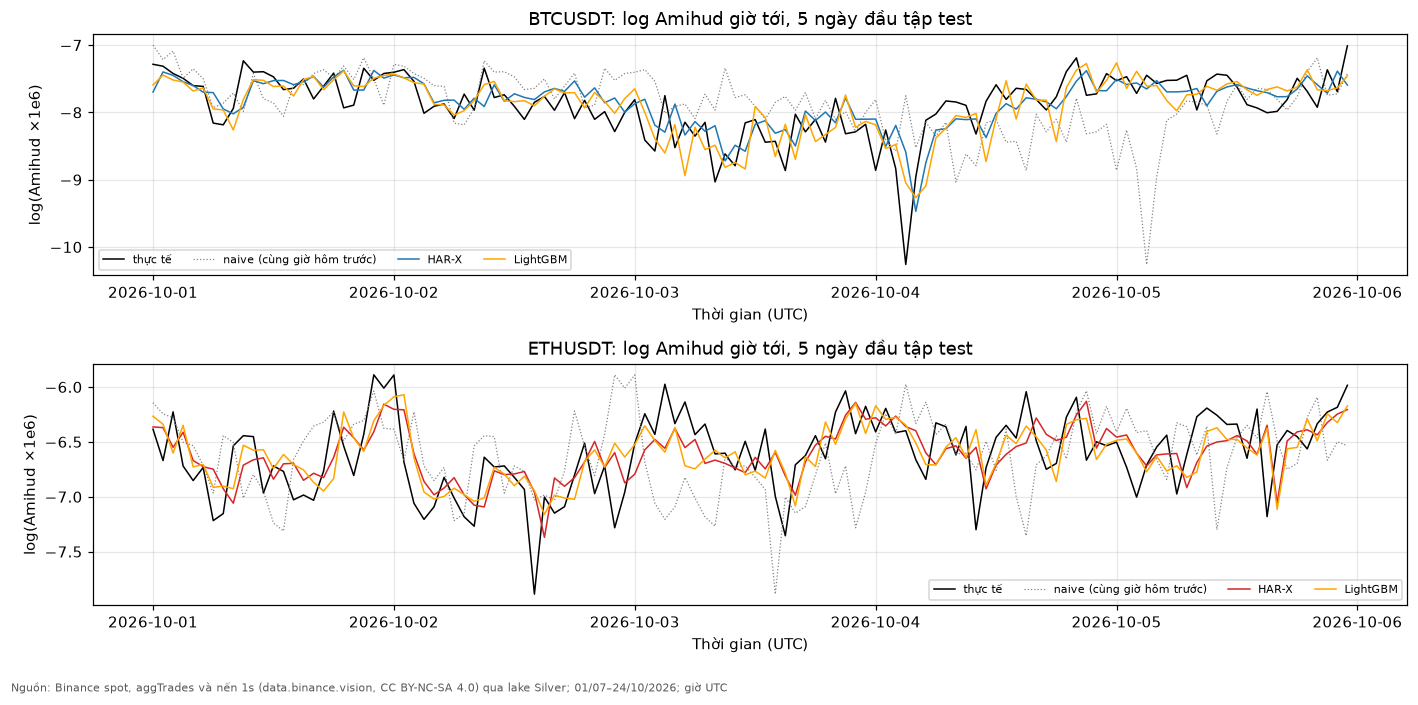

In [22]:
fig, axes = plt.subplots(len(PRED), 1, figsize=(13, 3.2 * len(PRED)), squeeze=False)
for ax, (s, out) in zip(axes[:, 0], PRED.items()):
    w = out.loc[out.index < out.index.min() + pd.Timedelta("5D")]
    ax.plot(w.index, w["y"], color="k", lw=1, label="thực tế")
    ax.plot(w.index, w["B1_naive"], color="grey", lw=.8, ls=":", label="naive (cùng giờ hôm trước)")
    ax.plot(w.index, w["HAR_X"], color=COL.get(s), lw=1, label="HAR-X")
    ax.plot(w.index, w["LightGBM"], color="orange", lw=1, label="LightGBM")
    ax.set_title(f"{s}: log Amihud giờ tới, 5 ngày đầu tập test"); ax.legend(fontsize=7, ncol=4)
    ax.set_ylabel("log(Amihud ×1e6)"); ax.set_xlabel("Thời gian (UTC)")
finish(fig); fig.savefig(FIG_DIR / "model_forecast_test.png", bbox_inches="tight")

In [23]:
pd.concat(RES, names=["symbol"]).to_csv(RES_DIR / "model_amihud_forecast_holdout.csv")
pd.concat(WF, names=["symbol"]).to_csv(RES_DIR / "model_amihud_forecast_walkforward.csv")
FOLDS.to_csv(RES_DIR / "model_amihud_forecast_folds.csv", index=False)
ROBT.to_csv(RES_DIR / "model_period_robustness.csv")
LAM_HOD.to_csv(RES_DIR / "model_kyle_pooled_by_hour.csv")
VRS.to_csv(RES_DIR / "model_vr_by_session.csv", index=False)
cmp.to_csv(RES_DIR / "model_forecast_vs_seasonal.csv")
summary.to_csv(RES_DIR / "model_hourly_measures_summary.csv")
pd.concat(period_tab, names=["symbol"]).to_csv(RES_DIR / "model_calm_vs_volatile.csv")
print("saved")

saved


## 6b. Giới hạn của dữ liệu và phương pháp

| Giới hạn | Hệ quả cho kết luận |
|---|---|
| Một sàn (Binance), chỉ thị trường spot | Không phản ánh phân mảnh thanh khoản giữa các sàn, cũng không phản ánh futures/perp, nơi phần lớn khối lượng crypto giao dịch |
| Hai tài sản, đều thanh khoản rất cao (BTC, ETH) | Không suy ra được cho altcoin; phần DOGE đang được bổ sung |
| Khoảng 115 ngày (01/07–24/10/2026) | Mỗi giai đoạn so sánh chỉ là 1 tháng; tập test dự báo chỉ 24 ngày (holdout) hoặc 8 tuần (walk-forward) |
| Không có quote và depth (sổ lệnh) | Không đo được quoted spread hay độ sâu; Roll, CS, AR chỉ là **proxy** cho spread hiệu dụng; **không có bộ dự phòng**: LOBSTER (bộ dự phòng theo đề) không truy cập được khi thử tải ngày 25/10/2026 (link mẫu hỏng, phải xin bằng email học thuật); kết quả AAPL 21/06/2012 chạy trước đó lấy từ tệp không còn kiểm chứng được nên không dùng |
| aggTrades gộp các lệnh khớp cùng giá | Roll bị chệch (cov > 0 ở 74–79% số giờ); OFI là dòng lệnh chủ động, không phải OFI theo quote của Cont et al. |
| Kyle λ ước bằng OLS, có thể nội sinh | Gộp theo giờ, bin 10s, có lag và sai số cụm theo ngày giúp giảm nhưng không loại bỏ được sai số đo |
| Kiểm định VR có sức mạnh thấp | Không bác bỏ bước ngẫu nhiên không có nghĩa là thị trường hiệu quả |
| Không có dữ liệu sự kiện (tin vĩ mô, thanh lý) | Không giải thích được nguyên nhân của các chênh lệch giữa hai giai đoạn |
| Không áp dụng trực tiếp cho thị trường Việt Nam | Biên độ giá, phiên ATO/ATC, T+2 và tick size làm vi cấu trúc thị trường khác hẳn |

## 7. Kết luận (số liệu chạy ngày 25/10/2026, dữ liệu 01/07 đến 24/10/2026, BTCUSDT và ETHUSDT trên Binance spot)

1. **Hồ sơ theo giờ phụ thuộc vào thước đo được chọn.** CS, AR, realized vol và volume cùng đạt đỉnh lúc 14h UTC (giờ chồng London–New York) và thấp nhất lúc 04–06h UTC; tương quan giữa các hồ sơ 24 giờ là 0,86–0,99. Điều này khớp với Brauneis et al. (2024) và Su et al. (2022): spread hiệu dụng rộng nhất đúng lúc thị trường sôi động nhất. Ngược lại, Amihud cao nhất lúc 00–01h và thấp nhất lúc 07h UTC, tương quan âm với volume (−0,58 với BTC, −0,73 với ETH). Amihud đo tác động giá trên mỗi USD, nên giờ volume thấp cho Amihud cao một cách cơ học. Kết luận: *chi phí spread cao nhất ở phiên Mỹ, còn tác động giá trên mỗi USD cao nhất ở đêm châu Á.* Hai họ thước đo trả lời hai câu hỏi khác nhau.
2. **ETH so với BTC:** Kyle λ gộp (bin 10s, sai số cụm theo ngày) là 2,8 bps/M với BTC và 7,8 bps/M với ETH. Tính theo USD, ETH đắt gấp khoảng 2,8 lần. Nhưng λ chuẩn hoá (λ·σ_flow/σ_r) gần như bằng nhau: 0,43 [0,38; 0,47] với BTC và 0,41 [0,35; 0,47] với ETH. Như vậy **chênh lệch BTC–ETH tính theo USD chủ yếu do thang volume**: cùng một lượng dòng lệnh tính theo độ lệch chuẩn thì gây biến động giá tương đương ở hai tài sản. Muốn so chất lượng thị trường giữa các tài sản phải dùng dạng chuẩn hoá.
3. **Tháng 8 so với tháng 9: không có hiệu bền.** Volume tăng 33% với BTC và 99% với ETH, realized vol tăng khoảng 35%. Nhưng với block bootstrap theo ngày, CI 95% của Amihud, CS, AR và volume đều chứa 0. Placebo nửa đầu so với nửa sau *trong* tháng 8 cho hiệu còn lớn hơn hiệu giữa hai tháng (volume +63% với BTC và +161% với ETH). Mức giảm Amihud trong tháng 9 mà phiên bản trước báo cáo (Mann–Whitney p=0,003 với ETH) **không bền** khi tính đến tự tương quan và nhiễu lịch. Notebook không đưa ra kết luận nhân quả về tác động của biến động lên thanh khoản.
4. **Hiệu quả giá:** tính trên cả ngày, VR(5), VR(15), VR(60) đều xấp xỉ 1. Tách theo phiên (CI bootstrap theo ngày) thì khác: **phiên Á có mean reversion** ở q=60 phút, VR = 0,89 [0,79; 0,98] với BTC và 0,76 [0,67; 0,86] với ETH; ETH cũng có ở q=15. Phiên Mỹ của BTC có VR(15) = 0,90 [0,84; 0,95]. Phiên Âu có VR hơi trên 1 nhưng không có ý nghĩa. Có 18 kiểm định nên khoảng 1 kết quả có thể là dương tính giả; kết quả bền nhất là phiên Á của ETH ở q=60. Mean reversion trong phiên thanh khoản thấp phù hợp với tác động giá tạm thời rồi hồi lại. Các ô không bác bỏ không có nghĩa là thị trường hiệu quả, vì kiểm định có sức mạnh thấp.
5. **Roll:** hiệp phương sai dương ở 74–79% số giờ, vì aggTrades là giao dịch chủ động và thiếu bid-ask bounce. Spread chính được đo bằng CS và AR (theo Brauneis et al. 2021).
6. **Dự báo log-Amihud giờ tới, baseline chính là giờ liền trước (B0).** Trên tập test 1–24/10, HAR đạt R²_OOS 0,20 với BTC và 0,13 với ETH. HAR + dummy giờ đạt 0,23 và 0,14. DM với hiệu chỉnh HLN có p < 0,03. Walk-forward 8 fold (01/09–24/10): HAR_hod thắng B0 ở 8/8 fold với BTC (R² trung bình 0,24) và 7/8 fold với ETH (0,19); fold 06/10 của ETH thua. **LightGBM không hơn B0 với ETH** (holdout p = 0,88, walk-forward p = 0,09), và không hơn HAR ở bất kỳ tài sản nào. So với đối thủ công bằng là B2 (trung bình cùng giờ trên train), HAR_hod đạt R²_OOS 0,55 với BTC và 0,57 với ETH (DM p ≤ 0,002). Tuy vậy, B2 yếu hơn cả B0, và dummy giờ chỉ thêm 0,03 R² (BTC) và 0,002 (ETH) so với HAR. **Phần lớn khả năng dự báo đến từ quán tính thanh khoản (Amihud giờ trước và các trung bình trễ), không phải từ mùa vụ theo giờ.** Mẫu hình theo giờ có ý nghĩa thống kê nhưng nhỏ so với dao động giữa các giờ. Phụ lục: so với baseline "cùng giờ hôm trước", R²_OOS là 0,68–0,74, nhưng baseline này yếu nên con số đó không được dùng làm kết quả chính.

**Giới hạn:** Binance spot không có quote và depth, nên mọi thước đo spread đều là proxy; chỉ có 2 tài sản thanh khoản cao trên 1 sàn; mỗi giai đoạn chỉ là 1 tháng; tập test ngắn. Kết quả không ngoại suy được sang cổ phiếu Việt Nam (biên độ giá, phiên ATO/ATC, T+2, tick size).

**Tài liệu:** Brauneis, Mestel, Riordan & Theissen (2021, *JBF*; 2024, *RQFA*); Su et al. (2022, *RIBAF*); Wątorek et al. (2023, *Chaos*); Shen et al. (2021, *Financial Review*); Miłobędzki (2023); Amihud (2002); Corwin & Schultz (2012); Abdi & Ranaldo (2017); Lo & MacKinlay (1988); Harvey, Leybourne & Newbold (1997); Corsi (2009).